In [1]:
from lempel_ziv_complexity import lempel_ziv_complexity

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.cluster import KMeans

In [4]:
import pandas as pd
%matplotlib inline
from scipy import ndimage
from scipy.optimize import curve_fit

from sklearn.neighbors import KernelDensity
from math import log,log2
import statsmodels.formula.api as smf
import random

In [5]:
bats = pd.read_csv('data/Kershenbaum_et_al_2014_Bat.csv', header=None, dtype=np.float64)
chickadees = pd.read_csv('data/Kershenbaum_et_al_2014_Chickadee.csv', header=None, dtype=np.float64)
humansEnglishUnformated = pd.read_csv('data/Kershenbaum_et_al_2014_English.csv', header=None, dtype=np.float64)
finches = pd.read_csv('data/Kershenbaum_et_al_2014_Finch.csv', header=None, dtype=np.float64)
hyraxes = pd.read_csv('data/Kershenbaum_et_al_2014_Hyrax.csv', header=None, dtype=np.float64)
orangutans = pd.read_csv('data/Kershenbaum_et_al_2014_Orangutan.csv', header=None, dtype=np.float64)
orcasUnformated = pd.read_csv('data/Kershenbaum_et_al_2014_Orca.csv', header=None, dtype=np.float64)
pilotsUnformated = pd.read_csv('data/Kershenbaum_et_al_2014_Pilot.csv', header=None, dtype=np.float64)
whalesDia = pd.read_csv('data/Sharma_et_al_2024_WhaleDialogues.csv')
whalesDom = pd.read_csv('data/Sharma_et_al_2024_WhaleDominica.csv')

In [6]:
englishTranslator = dict()
englishVocabSize = 0
humansEnglish = humansEnglishUnformated.copy() 

for i in range(len(humansEnglishUnformated)):
    for j in range(len(humansEnglishUnformated.iloc[i].dropna())):
        if (humansEnglishUnformated.iloc[i,j] not in englishTranslator):
            englishVocabSize += 1
            englishTranslator[humansEnglishUnformated.iloc[i,j]] = np.float64(englishVocabSize)
        humansEnglish.iloc[i,j] = englishTranslator[humansEnglishUnformated.iloc[i,j]]

orcasTranslator = dict()
orcasVocabSize = 0
orcas = orcasUnformated.copy() 

for i in range(len(orcasUnformated)):
    for j in range(len(orcasUnformated.iloc[i].dropna())):
        if (orcasUnformated.iloc[i,j] not in orcasTranslator):
            orcasVocabSize += 1
            orcasTranslator[orcasUnformated.iloc[i,j]] = np.float64(orcasVocabSize)
        orcas.iloc[i,j] = orcasTranslator[orcasUnformated.iloc[i,j]]

pilotsTranslator = dict()
pilotsVocabSize = 0
pilots = pilotsUnformated.copy() 

for i in range(len(pilotsUnformated)):
    for j in range(len(pilotsUnformated.iloc[i].dropna())):
        if (pilotsUnformated.iloc[i,j] not in pilotsTranslator):
            pilotsVocabSize += 1
            pilotsTranslator[pilotsUnformated.iloc[i,j]] = np.float64(pilotsVocabSize)
        pilots.iloc[i,j] = pilotsTranslator[pilotsUnformated.iloc[i,j]]

def relabelData(dataUnformated):
    translator = dict()
    vocabSize = 0
    data = dataUnformated.copy() 
    for i in range(len(dataUnformated)):
        for j in range(len(dataUnformated.iloc[i].dropna())):
            if (dataUnformated.iloc[i,j] not in translator):
                vocabSize += 1
                translator[dataUnformated.iloc[i,j]] = np.float64(vocabSize)
            data.iloc[i,j] = translator[dataUnformated.iloc[i,j]]
    return data

In [7]:
whalesDia['Rhythm'] = -1
whalesDia['Ornementation'] = -1
whalesDia['Rubato'] = -1
whalesDia['Tempo'] = -1

In [8]:
whalesDia['prevNClicks'] = -1
whalesDia['nextNClicks'] = -1
whalesDia['prevDuration'] = -1.0
whalesDia['nextDuration'] = -1.0

In [9]:
def recWhaleCombo(i):
    return (whalesDia.iloc[i]['Whale'], whalesDia.iloc[i]['REC'])
 

prevDiaWhale_nClicks = dict()
nextDiaWhale_nClicks = dict()
prevDiaWhale_Duration = dict()
nextDiaWhale_Duration = dict()

for i in whalesDia.index:
    if recWhaleCombo(i) in prevDiaWhale_nClicks:
        whalesDia.loc[i,'prevNClicks'] = prevDiaWhale_nClicks[recWhaleCombo(i)]
    prevDiaWhale_nClicks[recWhaleCombo(i)] = whalesDia.iloc[i]['nClicks']

for i in reversed(whalesDia.index):
    if recWhaleCombo(i) in nextDiaWhale_nClicks:
        whalesDia.loc[i,'nextNClicks'] = nextDiaWhale_nClicks[recWhaleCombo(i)]
    nextDiaWhale_nClicks[recWhaleCombo(i)] = whalesDia.iloc[i]['nClicks']

whalesDia.loc[(whalesDia['prevNClicks']!=-1) & (whalesDia['nextNClicks']!=-1) & (whalesDia['nClicks']==whalesDia['prevNClicks']+1) & (whalesDia['nClicks']==whalesDia['nextNClicks']+1), 'Ornementation'] = 1
whalesDia.loc[(whalesDia['prevNClicks']!=-1) & (whalesDia['nextNClicks']==-1) & (whalesDia['nClicks']==whalesDia['prevNClicks']+1), 'Ornementation'] = 1
whalesDia.loc[(whalesDia['prevNClicks'] ==-1) & (whalesDia['nextNClicks']!=-1) & (whalesDia['nClicks']==whalesDia['nextNClicks']+1), 'Ornementation'] = 1
whalesDia.loc[(whalesDia['Ornementation'] != 1), 'Ornementation'] = 0


for i in whalesDia.index:
    if recWhaleCombo(i) in prevDiaWhale_Duration:
        whalesDia.loc[i,'prevDuration'] = prevDiaWhale_Duration[recWhaleCombo(i)]
    prevDiaWhale_Duration[recWhaleCombo(i)] = whalesDia.iloc[i]['Duration']

for i in reversed(whalesDia.index):
    if recWhaleCombo(i) in nextDiaWhale_Duration:
        whalesDia.loc[i,'nextDuration'] = nextDiaWhale_Duration[recWhaleCombo(i)]
    nextDiaWhale_Duration[recWhaleCombo(i)] = whalesDia.iloc[i]['Duration']

In [10]:
whalesDia['DurationWithOutOrnements'] = whalesDia['Duration']
whalesDia['nClicksWithOutOrnements'] = whalesDia['nClicks']

for i in whalesDia.index:
    if whalesDia.loc[i, 'Ornementation'] == 1:
        targetCol = f"ICI{int(whalesDia.loc[i, 'nClicks']) - 1}"
        whalesDia.loc[i, 'DurationWithOutOrnements'] = whalesDia.loc[i, 'DurationWithOutOrnements'] - whalesDia.loc[i, targetCol]

for i in whalesDia.index:
    if whalesDia.loc[i, 'Ornementation'] == 1:
        whalesDia.loc[i, 'nClicksWithOutOrnements'] = whalesDia.loc[i, 'nClicksWithOutOrnements'] - 1

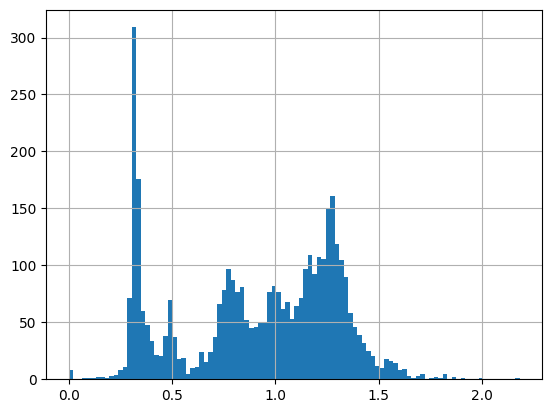

In [11]:
for i in whalesDia.index:
    if(whalesDia.loc[i, 'Duration'] < 21.5/46):
        whalesDia.loc[i, 'Tempo'] = 1
    elif(whalesDia.loc[i, 'Duration'] < 27.7/46):
         whalesDia.loc[i, 'Tempo'] = 2
    elif(whalesDia.loc[i, 'Duration'] < 41.5/46):
         whalesDia.loc[i, 'Tempo'] = 3
    elif(whalesDia.loc[i, 'Duration'] < 50.5/46):
         whalesDia.loc[i, 'Tempo'] = 4
    else:
        whalesDia.loc[i, 'Tempo'] = 5


whalesDia['Duration'].hist(bins=100) #bin range = 0.5/23 =0.021739130434782608


whalesDia['prevTempo'] = -1
whalesDia['nextTempo'] = -1
prevDiaWhale_Tempo = dict()
nextDiaWhale_Tempo = dict()

for i in whalesDia.index:
    if recWhaleCombo(i) in prevDiaWhale_Tempo:
        whalesDia.loc[i,'prevTempo'] = prevDiaWhale_Tempo[recWhaleCombo(i)]
    prevDiaWhale_Tempo[recWhaleCombo(i)] = whalesDia.iloc[i]['Tempo']

for i in reversed(whalesDia.index):
    if recWhaleCombo(i) in nextDiaWhale_Tempo:
        whalesDia.loc[i,'nextTempo'] = nextDiaWhale_Tempo[recWhaleCombo(i)]
    nextDiaWhale_Tempo[recWhaleCombo(i)] = whalesDia.iloc[i]['Tempo']


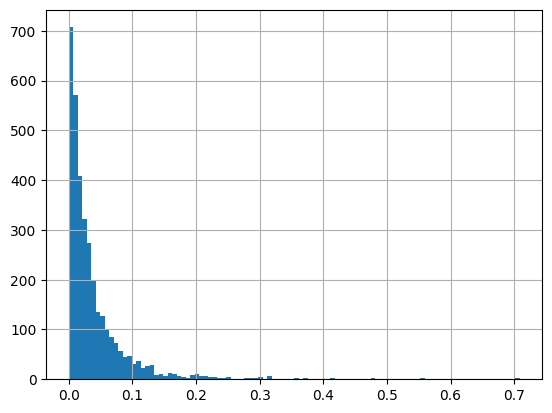

In [12]:
whalesDia['DurationDiff'] = -1.0

whalesDia.loc[whalesDia['Tempo'] == whalesDia['prevTempo'],'DurationDiff'] = np.abs(whalesDia['Duration']-whalesDia['prevDuration'])
whalesDia.loc[(whalesDia['Tempo'] != whalesDia['prevTempo']) & (whalesDia['Tempo'] == whalesDia['nextTempo']),'DurationDiff'] = np.abs(whalesDia['Duration']-whalesDia['nextDuration'])


whalesDia.loc[whalesDia['DurationDiff']!=-1.0,'DurationDiff'].hist(bins=100)

for i in whalesDia.index:
    if(whalesDia.loc[i, 'DurationDiff']>0.05):
        whalesDia.loc[i, 'Rubato'] = 1
    else:
        whalesDia.loc[i, 'Rubato'] = 0

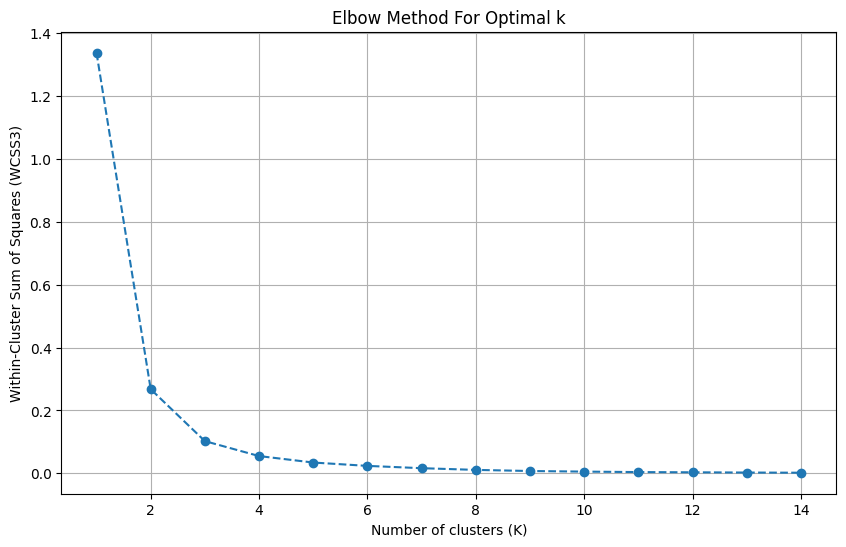

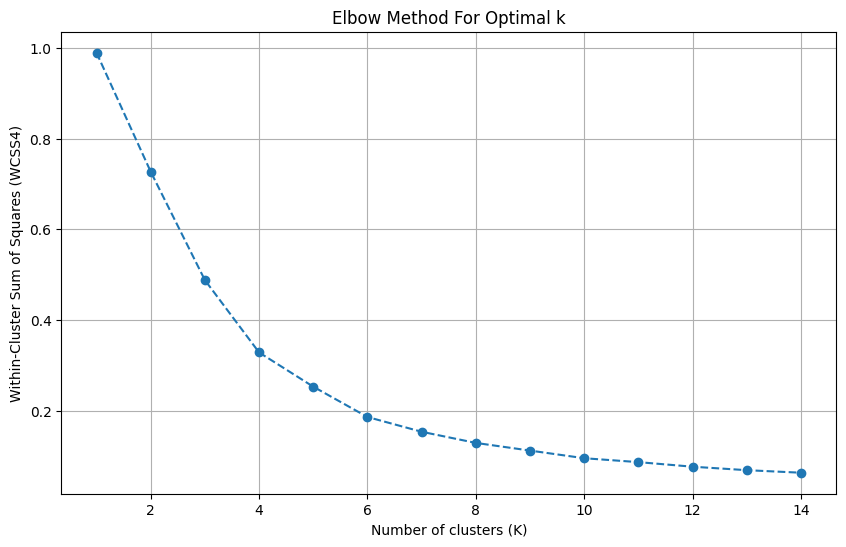

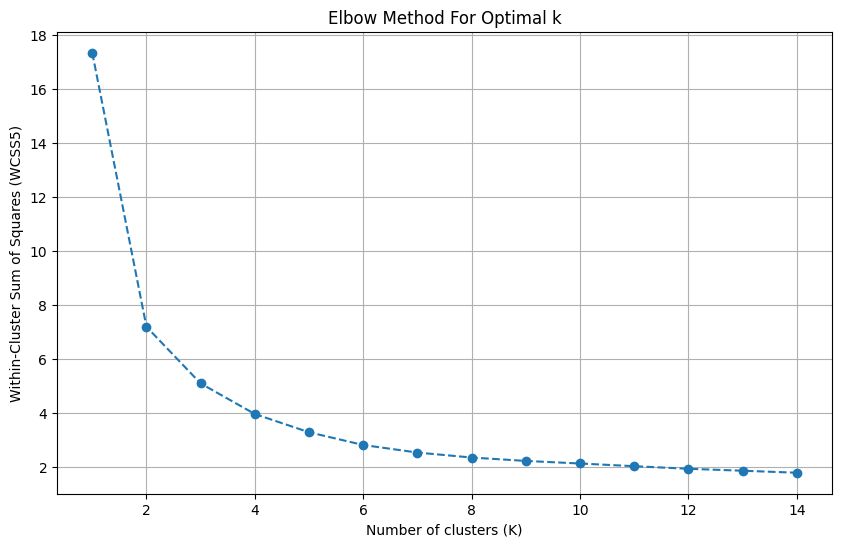

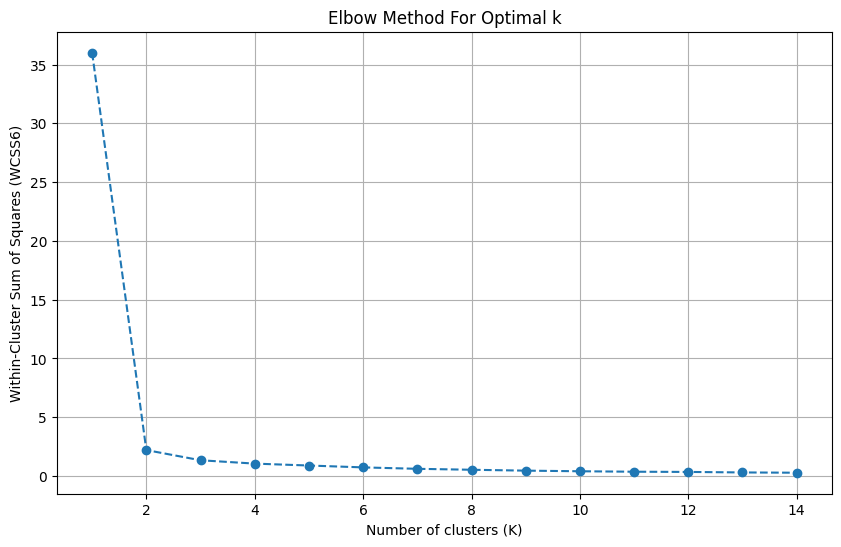

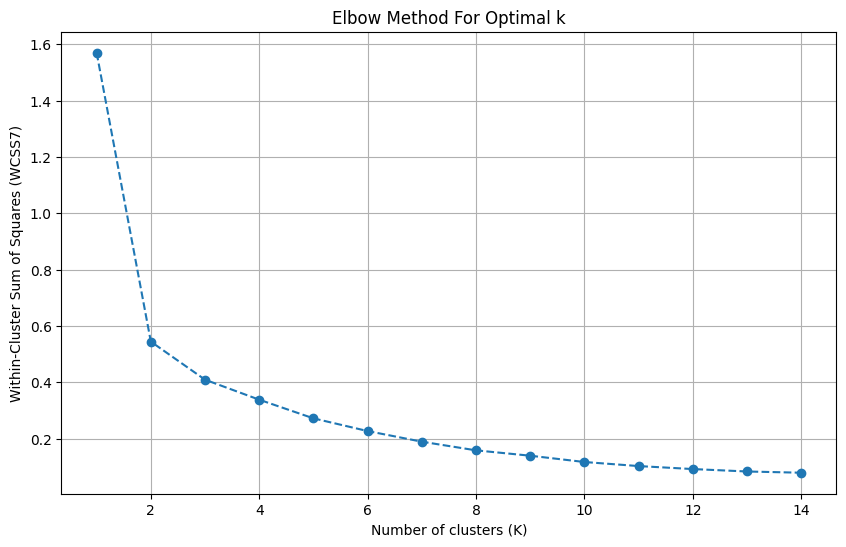

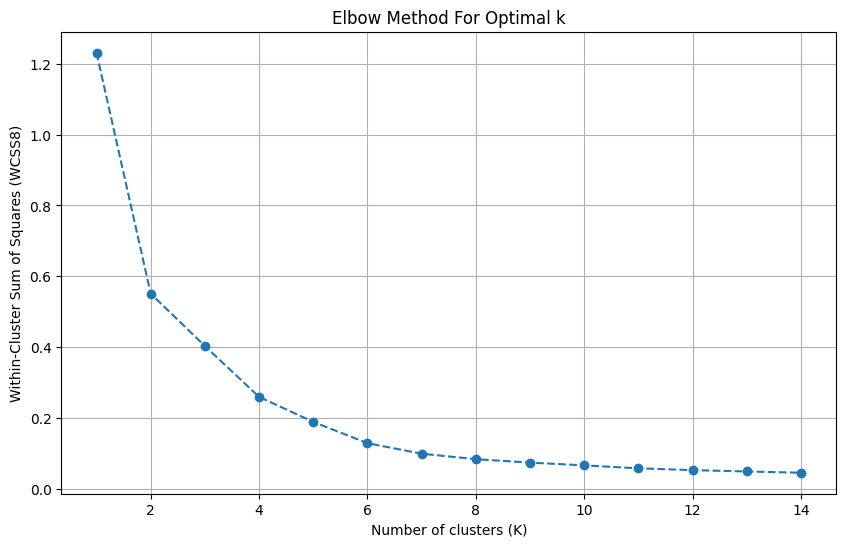

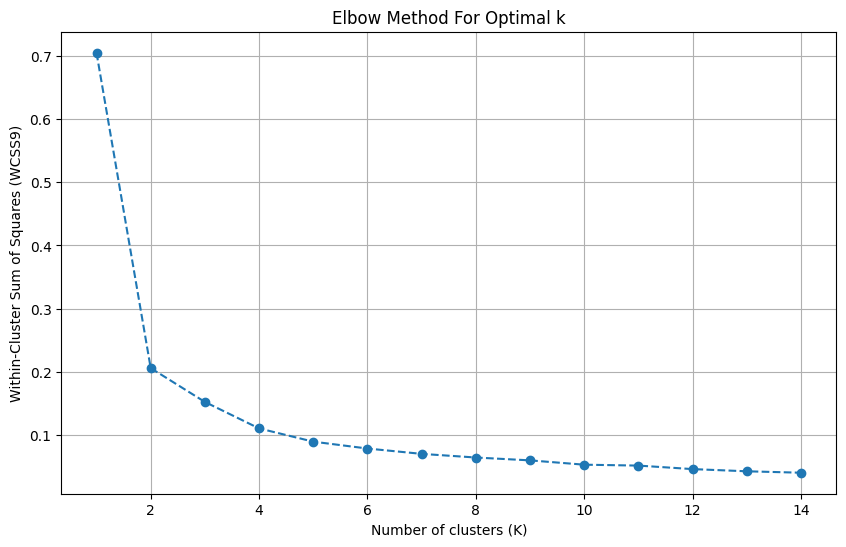

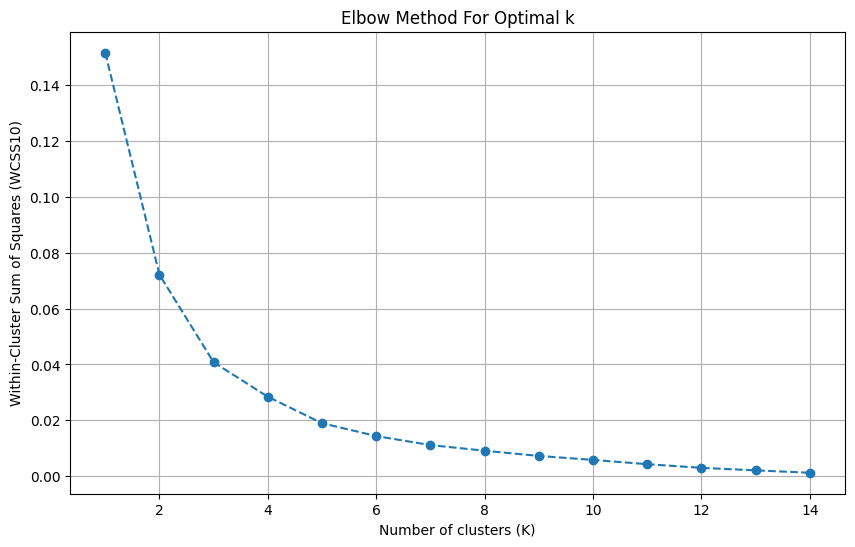

In [13]:
simpWhalesDia = whalesDia[whalesDia['nClicksWithOutOrnements'] <= 10]
simpWhalesDia = simpWhalesDia[['Duration', 'nClicks', 'ICI1', 'ICI2', 'ICI3', 'ICI4', 'ICI5', 'ICI6', 'ICI7', 'ICI8', 'ICI9']]
simpWhalesDom = whalesDom[['Duration', 'nClicks', 'ICI1', 'ICI2', 'ICI3', 'ICI4', 'ICI5', 'ICI6', 'ICI7', 'ICI8', 'ICI9']]
simpWhalesAll= pd.concat([simpWhalesDia,simpWhalesDom], ignore_index=True)


simpWhalesAll['Tempo'] = 0
simpWhalesAll['Rhythm'] = 0
simpWhalesAll['ICI1portion'] = 0.0
simpWhalesAll['ICI2portion'] = 0.0
simpWhalesAll['ICI3portion'] = 0.0
simpWhalesAll['ICI4portion'] = 0.0
simpWhalesAll['ICI5portion'] = 0.0
simpWhalesAll['ICI6portion'] = 0.0
simpWhalesAll['ICI7portion'] = 0.0
simpWhalesAll['ICI8portion'] = 0.0
simpWhalesAll['ICI9portion'] = 0.0
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI1portion'] = simpWhalesAll['ICI1']/simpWhalesAll['Duration']
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI2portion'] = simpWhalesAll['ICI2']/simpWhalesAll['Duration']
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI3portion'] = simpWhalesAll['ICI3']/simpWhalesAll['Duration']
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI4portion'] = simpWhalesAll['ICI4']/simpWhalesAll['Duration']
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI5portion'] = simpWhalesAll['ICI5']/simpWhalesAll['Duration']
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI6portion'] = simpWhalesAll['ICI6']/simpWhalesAll['Duration']
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI7portion'] = simpWhalesAll['ICI7']/simpWhalesAll['Duration']
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI8portion'] = simpWhalesAll['ICI8']/simpWhalesAll['Duration']
simpWhalesAll.loc[simpWhalesAll['nClicks'] > 1, 'ICI9portion'] = simpWhalesAll['ICI9']/simpWhalesAll['Duration']

WhalesOneClickAll = simpWhalesAll[simpWhalesAll['nClicks']==1]
WhalesTwoClickAll = simpWhalesAll[simpWhalesAll['nClicks']==2]
WhalesTreeClickAll = simpWhalesAll[simpWhalesAll['nClicks']==3]
WhalesFourClickAll = simpWhalesAll[simpWhalesAll['nClicks']==4]
WhalesFiveClickAll = simpWhalesAll[simpWhalesAll['nClicks']==5]
WhalesSixClickAll = simpWhalesAll[simpWhalesAll['nClicks']==6]
WhalesSevenClickAll = simpWhalesAll[simpWhalesAll['nClicks']==7]
WhalesEightClickAll = simpWhalesAll[simpWhalesAll['nClicks']==8]
WhalesNineClickAll = simpWhalesAll[simpWhalesAll['nClicks']==9]
WhalesTenClickAll = simpWhalesAll[simpWhalesAll['nClicks']==10]

simpWhalesDia['Tempo'] = 0
simpWhalesDia['Rhythm'] = 0
simpWhalesDia['ICI1portion'] = 0.0
simpWhalesDia['ICI2portion'] = 0.0
simpWhalesDia['ICI3portion'] = 0.0
simpWhalesDia['ICI4portion'] = 0.0
simpWhalesDia['ICI5portion'] = 0.0
simpWhalesDia['ICI6portion'] = 0.0
simpWhalesDia['ICI7portion'] = 0.0
simpWhalesDia['ICI8portion'] = 0.0
simpWhalesDia['ICI9portion'] = 0.0
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI1portion'] = simpWhalesDia['ICI1']/simpWhalesDia['Duration']
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI2portion'] = simpWhalesDia['ICI2']/simpWhalesDia['Duration']
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI3portion'] = simpWhalesDia['ICI3']/simpWhalesDia['Duration']
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI4portion'] = simpWhalesDia['ICI4']/simpWhalesDia['Duration']
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI5portion'] = simpWhalesDia['ICI5']/simpWhalesDia['Duration']
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI6portion'] = simpWhalesDia['ICI6']/simpWhalesDia['Duration']
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI7portion'] = simpWhalesDia['ICI7']/simpWhalesDia['Duration']
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI8portion'] = simpWhalesDia['ICI8']/simpWhalesDia['Duration']
simpWhalesDia.loc[simpWhalesDia['nClicks'] > 1, 'ICI9portion'] = simpWhalesDia['ICI9']/simpWhalesDia['Duration']

WhalesOneClickDia = simpWhalesDia[simpWhalesDia['nClicks']==1]
WhalesTwoClickDia = simpWhalesDia[simpWhalesDia['nClicks']==2]
WhalesThreeClickDia = simpWhalesDia[simpWhalesDia['nClicks']==3]
WhalesFourClickDia = simpWhalesDia[simpWhalesDia['nClicks']==4]
WhalesFiveClickDia = simpWhalesDia[simpWhalesDia['nClicks']==5]
WhalesSixClickDia = simpWhalesDia[simpWhalesDia['nClicks']==6]
WhalesSevenClickDia = simpWhalesDia[simpWhalesDia['nClicks']==7]
WhalesEightClickDia = simpWhalesDia[simpWhalesDia['nClicks']==8]
WhalesNineClickDia = simpWhalesDia[simpWhalesDia['nClicks']==9]
WhalesTenClickDia = simpWhalesDia[simpWhalesDia['nClicks']==10]

columnsUsedForKMeans = ['ICI1portion', 'ICI2portion', 'ICI3portion', 'ICI4portion', 'ICI5portion', 'ICI6portion', 'ICI7portion', 'ICI8portion', 'ICI9portion']

ReadyForKMeansWhalesDiaClick1 = WhalesOneClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick2 = WhalesTwoClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick3 = WhalesThreeClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick4 = WhalesFourClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick5 = WhalesFiveClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick6 = WhalesSixClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick7 = WhalesSevenClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick8 = WhalesEightClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick9 = WhalesNineClickDia[columnsUsedForKMeans]
ReadyForKMeansWhalesDiaClick10 = WhalesTenClickDia[columnsUsedForKMeans]

wcss3 = []
for k in range(1,15):
    kmeans3 = KMeans(n_clusters=k, init='k-means++', random_state=0, n_init=15)
    kmeans3.fit(ReadyForKMeansWhalesDiaClick3)
    wcss3.append(kmeans3.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 15), wcss3, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS3)')
plt.grid(True)
plt.show()

wcss4 = []
for k in range(1,15):
    kmeans4 = KMeans(n_clusters=k, init='k-means++', random_state=0, n_init=15)
    kmeans4.fit(ReadyForKMeansWhalesDiaClick4)
    wcss4.append(kmeans4.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 15), wcss4, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS4)')
plt.grid(True)
plt.show()


wcss5 = []
for k in range(1,15):
    kmeans5 = KMeans(n_clusters=k, init='k-means++', random_state=0, n_init=15)
    kmeans5.fit(ReadyForKMeansWhalesDiaClick5)
    wcss5.append(kmeans5.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 15), wcss5, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS5)')
plt.grid(True)
plt.show()

wcss6 = []
for k in range(1,15):
    kmeans6 = KMeans(n_clusters=k, init='k-means++', random_state=0, n_init=15)
    kmeans6.fit(ReadyForKMeansWhalesDiaClick6)
    wcss6.append(kmeans6.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 15), wcss6, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS6)')
plt.grid(True)
plt.show()

wcss7 = []
for k in range(1,15):
    kmeans7 = KMeans(n_clusters=k, init='k-means++', random_state=0, n_init=15)
    kmeans7.fit(ReadyForKMeansWhalesDiaClick7)
    wcss7.append(kmeans7.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 15), wcss7, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS7)')
plt.grid(True)
plt.show()

wcss8 = []
for k in range(1,15):
    kmeans8 = KMeans(n_clusters=k, init='k-means++', random_state=0, n_init=15)
    kmeans8.fit(ReadyForKMeansWhalesDiaClick8)
    wcss8.append(kmeans8.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 15), wcss8, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS8)')
plt.grid(True)
plt.show()

wcss9 = []
for k in range(1,15):
    kmeans9 = KMeans(n_clusters=k, init='k-means++', random_state=0, n_init=15)
    kmeans9.fit(ReadyForKMeansWhalesDiaClick9)
    wcss9.append(kmeans9.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 15), wcss9, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS9)')
plt.grid(True)
plt.show()

wcss10 = []
for k in range(1,15):
    kmeans10 = KMeans(n_clusters=k, init='k-means++', random_state=0, n_init=15)
    kmeans10.fit(ReadyForKMeansWhalesDiaClick10)
    wcss10.append(kmeans10.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 15), wcss10, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS10)')
plt.grid(True)
plt.show()
simpWhalesDia = whalesDia[whalesDia['nClicksWithOutOrnements'] <= 10]
simpWhalesDia = simpWhalesDia[['Duration', 'nClicks', 'ICI1', 'ICI2', 'ICI3', 'ICI4', 'ICI5', 'ICI6', 'ICI7', 'ICI8', 'ICI9']]
simpWhalesDom = whalesDom[['Duration', 'nClicks', 'ICI1', 'ICI2', 'ICI3', 'ICI4', 'ICI5', 'ICI6', 'ICI7', 'ICI8', 'ICI9']]
simpWhalesAll= pd.concat([simpWhalesDia,simpWhalesDom], ignore_index=True)

In [14]:
WhalesOneClickDia['Rythm'] = 0
WhalesTwoClickDia['Rythm'] = 0
WhalesThreeClickDia['Rythm'] = 0
WhalesFourClickDia['Rythm'] = 0
WhalesFiveClickDia['Rythm'] = 0
WhalesSixClickDia['Rythm'] = 0
WhalesSevenClickDia['Rythm'] = 0
WhalesEightClickDia['Rythm'] = 0
WhalesNineClickDia['Rythm'] = 0
WhalesTenClickDia['Rythm'] = 0

In [15]:
kmeans3 = KMeans(n_clusters=2, init='k-means++', random_state=0, n_init=15)
kmeans4 = KMeans(n_clusters=4, init='k-means++', random_state=0, n_init=15)
kmeans5 = KMeans(n_clusters=2, init='k-means++', random_state=0, n_init=15)
kmeans6 = KMeans(n_clusters=2, init='k-means++', random_state=0, n_init=15)
kmeans7 = KMeans(n_clusters=2, init='k-means++', random_state=0, n_init=15)
kmeans8 = KMeans(n_clusters=2, init='k-means++', random_state=0, n_init=15)
kmeans9 = KMeans(n_clusters=2, init='k-means++', random_state=0, n_init=15)
kmeans10 = KMeans(n_clusters=3, init='k-means++', random_state=0, n_init=15)

clusters3 = kmeans3.fit_predict(ReadyForKMeansWhalesDiaClick3)
clusters4 = kmeans4.fit_predict(ReadyForKMeansWhalesDiaClick4)
clusters5 = kmeans5.fit_predict(ReadyForKMeansWhalesDiaClick5)
clusters6 = kmeans6.fit_predict(ReadyForKMeansWhalesDiaClick6)
clusters7 = kmeans7.fit_predict(ReadyForKMeansWhalesDiaClick7)
clusters8 = kmeans8.fit_predict(ReadyForKMeansWhalesDiaClick8)
clusters9 = kmeans9.fit_predict(ReadyForKMeansWhalesDiaClick9)
clusters10 = kmeans10.fit_predict(ReadyForKMeansWhalesDiaClick10)

WhalesOneClickDia['Rythm'] = 1
WhalesTwoClickDia['Rythm'] = 2
WhalesThreeClickDia['Rythm'] = clusters3 +1
WhalesFourClickDia['Rythm'] = clusters4 +1
WhalesFiveClickDia['Rythm'] = clusters5 +1
WhalesSixClickDia['Rythm'] = clusters6 +1
WhalesSevenClickDia['Rythm'] = clusters7 +1
WhalesEightClickDia['Rythm'] = clusters8 +1
WhalesNineClickDia['Rythm'] = clusters9 +1
WhalesTenClickDia['Rythm'] = clusters10 +1

In [16]:
indexInWhalesOneClickDia = 0
indexInWhalesTwoClickDia = 0
indexInWhalesThreeClickDia = 0
indexInWhalesFourClickDia = 0
indexInWhalesFiveClickDia = 0
indexInWhalesSixClickDia = 0
indexInWhalesSevenClickDia = 0
indexInWhalesEightClickDia = 0
indexInWhalesNineClickDia = 0
indexInWhalesTenClickDia = 0

WhalesThreeClickDia = WhalesThreeClickDia.reset_index(drop=True)
WhalesFourClickDia = WhalesFourClickDia.reset_index(drop=True)
WhalesFiveClickDia = WhalesFiveClickDia.reset_index(drop=True)
WhalesSixClickDia = WhalesSixClickDia.reset_index(drop=True)
WhalesSevenClickDia = WhalesSevenClickDia.reset_index(drop=True)
WhalesEightClickDia = WhalesEightClickDia.reset_index(drop=True)
WhalesNineClickDia = WhalesNineClickDia.reset_index(drop=True)
WhalesTenClickDia = WhalesTenClickDia.reset_index(drop=True)

for i in range(len(whalesDia)):
    if whalesDia.at[i, 'nClicks'] == 1:
        whalesDia.loc[i, 'Rythm'] = 1
        
    if whalesDia.at[i, 'nClicks'] == 2:
        whalesDia.loc[i, 'Rythm'] = 2
        
    if whalesDia.at[i, 'nClicks'] == 3:
        whalesDia.loc[i, 'Rythm'] = WhalesThreeClickDia.at[indexInWhalesThreeClickDia, 'Rythm']
        indexInWhalesThreeClickDia += 1;
        
    if whalesDia.at[i, 'nClicks'] == 4:
        whalesDia.loc[i, 'Rythm'] = WhalesFourClickDia.at[indexInWhalesFourClickDia, 'Rythm']
        indexInWhalesFourClickDia += 1;
        
    if whalesDia.at[i, 'nClicks'] == 5:
        whalesDia.loc[i, 'Rythm'] = WhalesFiveClickDia.at[indexInWhalesFiveClickDia, 'Rythm']
        indexInWhalesFiveClickDia += 1;
        
    if whalesDia.at[i, 'nClicks'] == 6:
        whalesDia.loc[i, 'Rythm'] = WhalesSixClickDia.at[indexInWhalesSixClickDia, 'Rythm']
        indexInWhalesSixClickDia += 1;
        
    if whalesDia.at[i, 'nClicks'] == 7:
        whalesDia.loc[i, 'Rythm'] = WhalesSevenClickDia.at[indexInWhalesSevenClickDia, 'Rythm']
        indexInWhalesSevenClickDia += 1;
        
    if whalesDia.at[i, 'nClicks'] == 8:
        whalesDia.loc[i, 'Rythm'] = WhalesEightClickDia.at[indexInWhalesEightClickDia, 'Rythm']
        indexInWhalesEightClickDia += 1;
        
    if whalesDia.at[i, 'nClicks'] == 9:
        whalesDia.loc[i, 'Rythm'] = WhalesNineClickDia.at[indexInWhalesNineClickDia, 'Rythm']
        indexInWhalesNineClickDia += 1;
        
    if whalesDia.at[i, 'nClicks'] == 10:
        whalesDia.loc[i, 'Rythm'] = WhalesTenClickDia.at[indexInWhalesTenClickDia, 'Rythm']
        indexInWhalesTenClickDia += 1;

In [17]:
simpleWhalesDia = whalesDia[['REC', 'Ornementation','Rhythm','Tempo','Rubato']].copy()
simpleWhalesDia['CodaType'] = 0
codaTypeDescriptions = {}
numCodaTypes = 0
for i in simpleWhalesDia.index:
    features = (
        simpleWhalesDia.at[i, 'Ornementation'],
        simpleWhalesDia.at[i, 'Rhythm'],
        simpleWhalesDia.at[i, 'Tempo'],
        simpleWhalesDia.at[i, 'Rubato']
    )
    
    if features in codaTypeDescriptions:
        simpleWhalesDia.at[i, 'CodaType'] = codaTypeDescriptions[features]
    else:
        numCodaTypes += 1
        codaTypeDescriptions[features] = numCodaTypes
        simpleWhalesDia.at[i, 'CodaType'] = numCodaTypes

simplerWhalesDia = simpleWhalesDia[['REC', 'CodaType']].copy()

In [18]:
simplerWhalesDiaList = simplerWhalesDia.groupby('REC')['CodaType'].apply(list).reset_index()
simplerWhalesDiaList = simplerWhalesDia.groupby('REC')['CodaType'].apply(list).reset_index()
simplerWhalesDia['coda_num'] = simplerWhalesDia.groupby('REC').cumcount()
simplerWhalesDiaWide = simplerWhalesDia.pivot(index='REC', columns='coda_num', values='CodaType')
simplerWhalesDiaWide.columns = [f'Coda_{i+1}' for i in simplerWhalesDiaWide.columns]
simplerWhalesDiaWide = simplerWhalesDiaWide.reset_index(drop=True)
simplerWhalesDiaWide.index = simplerWhalesDiaWide.index + 1

In [19]:
def twoDDictionary(data):
    out = dict()
    keys = data.stack().unique()
    for k in keys:
        out[k] = dict()
        for l in keys:
            out[k][l] = 0
    return out

def threeDDictionary(data):
    out = dict()
    keys = data.stack().unique()
    for k in keys:
        out[k] = dict()
        for l in keys:
            out[k][l] = dict()
            for m in keys:
                out[k][l][m] = 0
    return out

def countSingles(data):
    counts = dict()
    for i in range(len(data)):
        for j in range(len(data.iloc[i].dropna())):
            if data.iloc[i,j] in counts:
                counts[data.iloc[i,j]] += 1
            else:
                counts[data.iloc[i,j]] = 1
    return counts
    
def countDoubles(data):
    counts = twoDDictionary(data)
    for i in range(len(data)):
        for j in range(len(data.iloc[i].dropna())-1):
            counts[data.iloc[i,j]][data.iloc[i,j+1]] += 1
    return counts
        
def countTriples(data):
    counts = threeDDictionary(data)
    for i in range(len(data)):
        for j in range(len(data.iloc[i].dropna())-2):
            counts[data.iloc[i,j]][data.iloc[i,j+1]][data.iloc[i,j+2]] += 1
    return counts
    
def N(data):
    return len(countSingles(data))

print(N(bats))
print(N(chickadees))
print(N(humansEnglish))
print(N(finches))
print(N(hyraxes))
print(N(orangutans))
print(N(orcas))
print(N(pilots))
print(N(simplerWhalesDiaWide))

3
7
23
7
5
7
28
17
18


In [20]:
def findTotalSingles(data):
    out = 0
    for i in range(len(data)):
        out += len(data.iloc[i].dropna())
    return out

def findTotalDoubles(data):
    out = 0
    for i in range(len(data)):
        out += max(0, (len(data.iloc[i].dropna())-1))
    return out

def findTotalTriples(data):
    out = 0
    for i in range(len(data)):
        out += max(0, (len(data.iloc[i].dropna())-2))
    return out

def totalNextsGivenSingle(doubles, single):
    return sum(doubles[single].values())
        
def totalNextsGivenDouble(triples, double1, double2):
    return sum(triples[double1][double2].values())

In [21]:
def findProb1(counts, sumCounts, first):
    # return counts[first]/sum(counts.values())
    return counts[first]/sumCounts
    
def findProb2 (doubles, first, second, totalDoubles):
    return doubles[first][second]/totalDoubles

def findProb3(triples, first, second, third, totalTriples):
    return triples[first][second][third]/totalTriples

def findProb1Given1(doubles, first, second):
    return  doubles[first][second]/totalNextsGivenSingle(doubles, first)

def findProb1Given2(triples, first, second, third):
    return  triples[first][second][third]/totalNextsGivenDouble(triples, first, second)



In [22]:
def H0(data):
    H = 0
    singles = countSingles(data)
    sumCounts = sum(singles.values())
    for i in singles:
        H -= findProb1(singles, sumCounts, i)*log2(findProb1(singles, sumCounts, i))
    return H

def H1helper(doubles, i, j, totalDoubles):
    prob1 = findProb2(doubles, i, j, totalDoubles)
    prob2 = findProb1Given1(doubles, i, j)
    if ((prob1 == 0.0) != (prob2 ==0.0)):
        raise ValueError("Disagreeing Probabilities")
    else:
        #print(f"{prob1}, {prob2}")
        return prob1 * log2(prob2)
    

def H1Quick(data, singles):
    H = 0
    doubles = countDoubles(data)
    totalDoubles = findTotalDoubles(data)
    for i in singles:
        for j in singles:
            if (findProb2(doubles, i, j, totalDoubles) != 0.0):
                H -= H1helper(doubles, i, j, totalDoubles)
    return H

def H1(data):
    singles = countSingles(data)
    return H1Quick(data, singles)

def H2helper(counts, i, j, k, totalTriples):
    prob1 = findProb3(counts, i, j, k, totalTriples)
    prob2 = findProb1Given2(counts, i, j, k)
    if ((prob1 == 0.0) != (prob2 ==0.0)):
        raise ValueError("Disagreeing Probabilities")
    else:
        return prob1 * log2(prob2)
        
def H2(data):
    H = 0
    singles = countSingles(data)
    triples = countTriples(data)
    totalTriples = findTotalTriples(data)
    for i in singles:
        for j in singles:
            for k in singles:
                if (findProb3(triples, i, j, k, totalTriples) != 0.0):
                    H -= H2helper(triples, i, j, k, totalTriples)
    return H

In [23]:
print(f"bats0: {H0(bats)}")
print(f"bats1: {H1(bats)}")
print(f"bats2: {H2(bats)}")

print(f"chickadees0: {H0(chickadees)}")
print(f"chickadees1: {H1(chickadees)}")
print(f"chickadees2: {H2(chickadees)}")

print(f"humansEnglish0: {H0(humansEnglish)}")
print(f"humansEnglish1: {H1(humansEnglish)}")
print(f"humansEnglish2: {H2(humansEnglish)}")

print(f"finches0: {H0(finches)}")
print(f"finches1: {H1(finches)}")
print(f"finches2: {H2(finches)}")

print(f"hyraxes0: {H0(hyraxes)}")
print(f"hyraxes1: {H1(hyraxes)}")
print(f"hyraxes2: {H2(hyraxes)}")

print(f"orangutans0: {H0(orangutans)}")
print(f"orangutans1: {H1(orangutans)}")
print(f"orangutans2: {H2(orangutans)}")

print(f"orcas0: {H0(orcas)}")
print(f"orcas1: {H1(orcas)}")
print(f"orcas2: {H2(orcas)}")

print(f"pilots0: {H0(pilots)}")
print(f"pilots1: {H1(pilots)}")
print(f"pilots2: {H2(pilots)}")

print(f"whales0: {H0(simplerWhalesDiaWide)}")
print(f"whales1: {H1(simplerWhalesDiaWide)}")
print(f"whales2: {H2(simplerWhalesDiaWide)}")

bats0: 1.58224575074237
bats1: 1.2537398820098369
bats2: 1.275439474652524
chickadees0: 1.8092933793578019
chickadees1: 0.7019804191674249
chickadees2: 0.45325001827923184
humansEnglish0: 4.074707251582271
humansEnglish1: 3.16110680824644
humansEnglish2: 1.8576003857605063
finches0: 2.5833038288700076
finches1: 1.022399713629694
finches2: 0.7477225729770001
hyraxes0: 2.0980040911312265
hyraxes1: 1.9254517986805362
hyraxes2: 1.8409137084707483
orangutans0: 2.001909079312914
orangutans1: 1.3126263105622518
orangutans2: 0.9626672236644043
orcas0: 3.7869116063530437
orcas1: 1.9367037934800404
orcas2: 1.2060576338154034
pilots0: 3.3540953746323074
pilots1: 2.214690931070862
pilots2: 1.3278664533538451
whales0: 2.967496355807498
whales1: 2.074959710328453
whales2: 1.6694767630555811


In [24]:
def NES(data):
    h0 = H0(data)
    singles = countSingles(data)
    n = N(data)
    return NESQuick(data, h0, n, singles)

def NESQuick(data, h0, n, singles):
    if(n>1):
        return (h0 - H1Quick(data, singles))/log2(n)
    else:
        return np.nan

print(f"batsNES: {NES(bats)}")

print(f"chickadeesNES: {NES(chickadees)}")

print(f"humansEnglishNES: {NES(humansEnglish)}")

print(f"finchesNES: {NES(finches)}")

print(f"hyraxesNES: {NES(hyraxes)}")

print(f"orangutansNES: {NES(orangutans)}")

print(f"orcasNES: {NES(orcas)}")

print(f"pilotsNES: {NES(pilots)}")

print(f"whalesNES: {NES(simplerWhalesDiaWide)}")


def randomizeSomeData(data, n, knownNumSingles):
    n = int(n)
    validCoords = np.argwhere(data.notna().values)
    if len(validCoords) != knownNumSingles:
        raise ValueError(f"Mismatch numSingles {knownNumSingles} {len(validCoords)}")
    if n > len(validCoords):
        n = len(validCoords)
    selectedIndices = np.random.choice(len(validCoords), size=n, replace=False)
    targetCoords = validCoords[selectedIndices]
    perm = np.random.permutation(len(targetCoords))
    dataResult = data.copy()
    for i, (r, c) in enumerate(targetCoords):
        permCoord = targetCoords[perm[i]]
        dataResult.iat[r, c] = data.iat[permCoord[0], permCoord[1]]
    return dataResult

batsNES: 0.20726412680619466
chickadeesNES: 0.39443283479767144
humansEnglishNES: 0.20196483483829084
finchesNES: 0.5560052642350882
hyraxesNES: 0.07431422740033686
orangutansNES: 0.2455274761787027
orcasNES: 0.3848702338127123
pilotsNES: 0.27875591480922335
whalesNES: 0.2140414144547756


In [25]:
def lempZivCompPerChar(data):
    total = 0 
    counts = countSingles(data)
    chars = sum(counts.values())
    for i in range(len(data)):
        tup = tuple(data.iloc[i].dropna())
        total += lempel_ziv_complexity(tup)
    return total/chars

def lempZivCompPerLine(data):
    total = 0 
    lines = len(data)
    for i in range(lines):
        tup = tuple(data.iloc[i].dropna())
        total += lempel_ziv_complexity(tup)
    return total/lines

def normedLempZivComp(data):
    total = 0 
    vocab = N(data)
    lines = len(data)
    if(vocab == 1):
        return np.nan
    else: 
        for i in range(lines):
            tup = tuple(data.iloc[i].dropna())
            if(len(data.iloc[i].dropna()) > 1):
                total += lempel_ziv_complexity(tup)/(len(data.iloc[i].dropna())/log(len(data.iloc[i].dropna()), vocab))
            else:
                lines -= 1
    return total/lines

print(lempZivCompPerChar(bats))
print(lempZivCompPerLine(bats))
print(normedLempZivComp(bats))

print(lempZivCompPerChar(chickadees))
print(lempZivCompPerLine(chickadees))
print(normedLempZivComp(chickadees))

print(lempZivCompPerChar(humansEnglish))
print(lempZivCompPerLine(humansEnglish))
print(normedLempZivComp(humansEnglish))

print(lempZivCompPerChar(finches))
print(lempZivCompPerLine(finches))
print(normedLempZivComp(finches))

print(lempZivCompPerChar(hyraxes))
print(lempZivCompPerLine(hyraxes))
print(normedLempZivComp(hyraxes))

print(lempZivCompPerChar(orangutans))
print(lempZivCompPerLine(orangutans))
print(normedLempZivComp(orangutans))

print(lempZivCompPerChar(orcas))
print(lempZivCompPerLine(orcas))
print(normedLempZivComp(orcas))

print(lempZivCompPerChar(pilots))
print(lempZivCompPerLine(pilots))
print(normedLempZivComp(pilots))

print(lempZivCompPerChar(simplerWhalesDiaWide))
print(lempZivCompPerLine(simplerWhalesDiaWide))
print(normedLempZivComp(simplerWhalesDiaWide))

0.7558912386706949
2.7861915367483294
0.9244776553078718
0.566348879154857
4.396
0.5953483146976933
0.8563941299790356
7.182417582417583
0.5757453377807392
0.6600531443755536
7.452
0.8132936433880391
0.5300364077669902
6.642585551330798
0.8223367484598606
0.46380697050938335
5.40625
0.583715737943717
0.463130659767141
12.785714285714286
0.4073522774089418
0.5454545454545454
9.428571428571429
0.514151406807602
0.43723958333333335
7.666666666666667
0.391629980524592


In [26]:
def zipfPLC(data):
    singles = countSingles(data)
    singlesSorted = []
    for i in singles:
        singlesSorted.append(singles[i])
    singlesSorted = sorted(singlesSorted)
    singlesSorted.reverse()
    logs = []
    for i in range(len(singlesSorted)):
        singlesSorted[i] = log(singlesSorted[i])
        logs.append(log(i+1))
    forLinearRegresion = pd.DataFrame({'x': logs, 'y': singlesSorted})
    model_fit = smf.ols('y ~ x', data=forLinearRegresion).fit()
    slope = model_fit.params['x']
    return slope

print(zipfPLC(bats))

print(zipfPLC(chickadees))

print(zipfPLC(humansEnglish))

print(zipfPLC(finches))

print(zipfPLC(hyraxes))

print(zipfPLC(orangutans))

print(zipfPLC(orcas))

print(zipfPLC(pilots))

print(zipfPLC(simplerWhalesDiaWide))

-0.12098167982347174
-2.551892651058458
-1.1471573029591664
-0.8955168631827428
-0.8470645423247793
-1.780842402793994
-1.6403801751619254
-1.4657910248933232
-2.1520343948455682


In [27]:
def randomMarkovChain0(vocabSize, length):
    transition = np.zeros((vocabSize), dtype=float)
    sum = 0
    for i in range(vocabSize):
        transition[i] = np.random.rand()
        sum += transition[i]
    for i in range(vocabSize):
            transition[i] /= sum
    series = np.zeros((length), dtype=int)
    for i in range(length):
        rand = np.random.rand()
        total = 0
        index = 0
        while total < rand:
            total += transition[index]
            index += 1
        series[i]=index
    return relabelData(pd.DataFrame([series]))

In [28]:
def randomMarkovChain1(vocabSize, length):
    transition = np.zeros((vocabSize,vocabSize), dtype=float)
    for i in range(vocabSize):
        sum = 0.0
        for j in range(vocabSize):
            transition[i,j] = np.random.rand()
            sum += transition[i,j]
        for j in range(vocabSize):
            transition[i,j] /= sum
    series = np.zeros((length), dtype=int)
    series[0] = np.random.randint(1,vocabSize+1)
    for i in range(1,length):
        rand = np.random.rand()
        total = 0.0
        index = 0
        while total < rand:
            total += transition[series[i-1]-1,index]
            index += 1
        series[i]=index
    return relabelData(pd.DataFrame(series).T)


In [29]:
def randomMarkovChain2(vocabSize, length):
    transition = np.zeros((vocabSize,vocabSize, vocabSize), dtype=float)
    for i in range(vocabSize):
        for j in range(vocabSize):
            sum = 0
            for k in range(vocabSize):
                transition[i,j,k] = np.random.rand()
                sum += transition[i,j,k]
            for k in range (vocabSize):
                transition[i,j,k] /= sum
    series = np.zeros((length), dtype=int)
    series[0] = np.random.randint(1,vocabSize+1)
    series[1] = np.random.randint(1,vocabSize+1)
    for i in range(2,length):
        rand = np.random.rand()
        total = 0
        index = 0
        while total < rand:
            total += transition[series[i-2]-1,series[i-1]-1,index]
            index += 1
        series[i]=index
    return relabelData(pd.DataFrame([series]))

In [30]:
def randomMarkovRenewalProsses(vocabSize, lengthOfBase, maxRepeat):
    base = randomMarkovChain1(vocabSize, lengthOfBase)
    probDistributions = np.zeros((vocabSize, maxRepeat), dtype = float)
    for i in range(vocabSize):
        sum = 0
        for j in range(maxRepeat):
            probDistributions[i,j] = np.random.rand()
            sum += probDistributions[i,j]
        for j in range(maxRepeat):
            probDistributions[i,j] /= sum
    seriesWithZeros = np.zeros((lengthOfBase*maxRepeat), dtype = int)
    pos = 0;
    for i in base.T[0]:
        rand = np.random.rand()
        total = 0
        index = 0
        while total < rand:
            total += probDistributions[i-1, index]
            index += 1
        for j in range(index):
            seriesWithZeros[pos] = i
            pos +=1
    series = seriesWithZeros[:pos]
    return relabelData(pd.DataFrame([series]))

In [31]:
def transitionMatrix(data, n):
    matrix = np.zeros((n,n), dtype = int)
    for i in range(len(data)):
        rowValues = data.iloc[i].dropna().astype(int).values
        for j in range(len(rowValues) - 1):
            currentState = rowValues[j] - 1
            nextState = rowValues[j+1] - 1
            matrix[currentState, nextState] += 1
    row_sums = matrix.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    return matrix/row_sums

def probs(data, n):
    array = np.zeros((n), dtype = int)
    for i in range(len(data)):
        rowValues = data.iloc[i].dropna().astype(int).values
        for j in range(len(rowValues)-1):
            array[rowValues[j]-1] += 1
    return array / array.sum()
        

def H1FromTransitionMatrix(matrix, probs):
    sum = 0.0
    for i in range(len(matrix)):
        for j in range(len(matrix[i])):
            if(matrix[i,j] != 0):
                sum -= probs[i]*matrix[i,j]*np.log2(matrix[i,j])
    return sum

In [32]:
def newNES(h0, probs, data, n):
    if(n>1):
        return (h0 - H1FromTransitionMatrix(transitionMatrix(data, n), probs))/np.log2(n)
    else:
        return 0

def NESPercentileValue(percentile, trials, data, percentRandom, thisProbs, h0, n, numSingles):
    numRandom = np.floor((percentRandom/100) * numSingles)
    results = np.zeros((trials), dtype = np.float64)
    for i in range(trials):
        randomData = randomizeSomeData(data, numRandom, numSingles)
        results[i] = newNES(h0, thisProbs ,randomData, n)
    results.sort()
    return results[int(percentile * trials)], np.mean(results), np.std(results)

In [33]:
def fExponential(t, A, B):
    return A * np.exp(-B * t)
    

def plotRandomNES(data, title, xLabel, yLabel):
    h0 = H0(data)
    n = N(data)
    thisProbs = probs(data, n)
    numSingles = findTotalSingles(data)
    values = np.zeros((100), dtype=np.float64)
    pRandoms = np.arange(len(values))
    for i in range(100):
        numRandom = int(findTotalSingles(data)*i/100)
        randomData = randomizeSomeData(data, numRandom,numSingles)
        values[i] = newNES(h0, thisProbs, randomData, n)
    paramsMean, paramsCov= curve_fit(fExponential, pRandoms, values)
    A = paramsMean[0]
    B = paramsMean[1]
    print(f"The equation for {title} is y = {A:.4f} e^({-B:.4f}p)")
    plt.plot(values)
    plt.plot(A * np.exp(-B * pRandoms))
    plt.title(title)
    plt.xlabel(xLabel)
    plt.ylabel(yLabel)
    plt.show()



def plotRandomOldNES(data, title, xLabel, yLabel):
    h0 = H0(data)
    n = N(data)
    thisProbs = probs(data, n)
    numSingles = findTotalSingles(data)
    singles = countSingles(data)
    values = np.zeros((100), dtype=np.float64)
    pRandoms = np.arange(len(values))
    for i in range(len(values)):
        numRandom = int(findTotalSingles(data)*i/len(values))
        randomData = randomizeSomeData(data, numRandom,numSingles)
        values[i] = NESQuick(randomData, h0, n, singles)
    #B , logA = np.polyfit(pRandoms, np.log(values), 1)
    #A=np.exp(logA)
    paramsMean, paramsCov= curve_fit(fExponential, pRandoms, values)
    A = paramsMean[0]
    B = paramsMean[1]
    print(f"The equation for {title} is y = {A:.4f} e^({-B:.4f}p)")
    plt.plot(values)
    plt.plot(A * np.exp(-B * pRandoms))
    plt.title(title)
    plt.xlabel(xLabel)
    plt.ylabel(yLabel)
    plt.show()

def newNESS(data):
    h0 = H0(data)
    n = N(data)
    thisProbs = probs(data, n)
    numSingles = findTotalSingles(data)
    values = np.zeros((100), dtype=np.float64)
    pRandoms = np.arange(len(values))
    for i in range(100):
        numRandom = int(findTotalSingles(data)*i/100)
        randomData = randomizeSomeData(data, numRandom,numSingles)
        values[i] = newNES(h0, thisProbs, randomData, n)
    paramsMean, paramsCov= curve_fit(fExponential, pRandoms, values)
    return paramsMean[1]

The equation for NES of Bats at Incrasing Randomization is y = 0.2084 e^(-0.0402p)


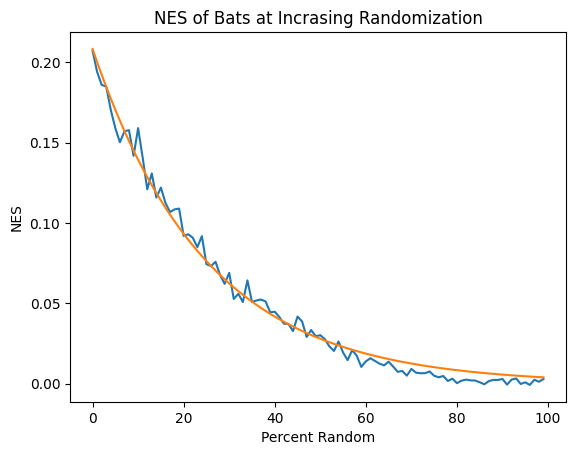

The equation for Chickadees is y = 0.3896 e^(-0.0379p)


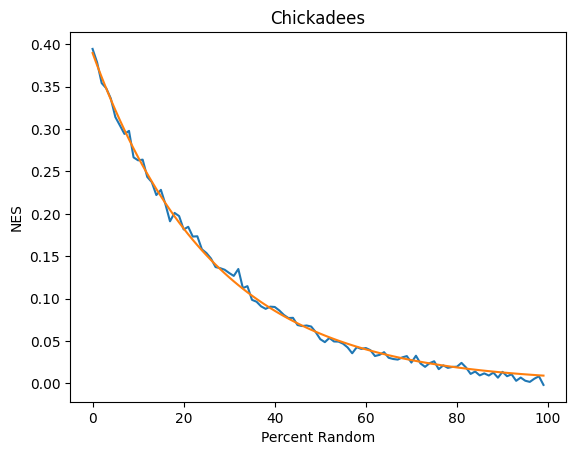

The equation for Humans (English) is y = 0.1887 e^(-0.0310p)


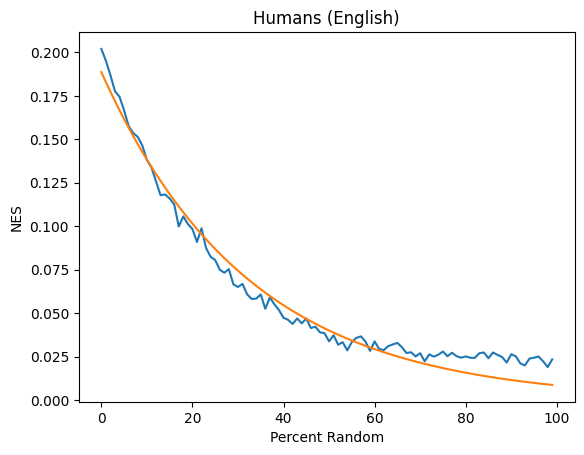

The equation for Finches is y = 0.5537 e^(-0.0464p)


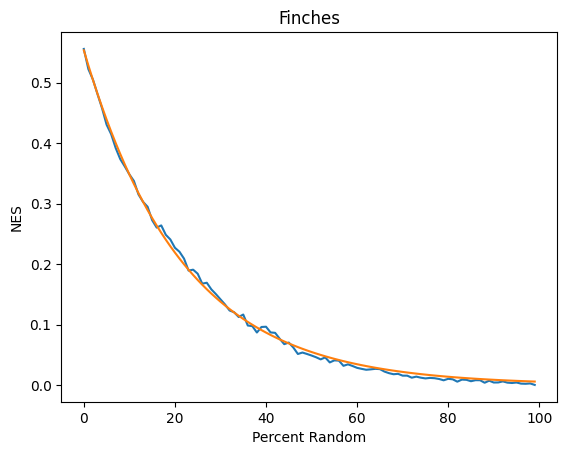

KeyboardInterrupt: 

In [34]:
plotRandomNES(bats, 'NES of Bats at Incrasing Randomization', 'Percent Random', 'NES')
plotRandomNES(chickadees, 'Chickadees', 'Percent Random', 'NES')
plotRandomNES(humansEnglish, 'Humans (English)', 'Percent Random', 'NES')
plotRandomNES(finches, 'Finches', 'Percent Random', 'NES')
plotRandomNES(hyraxes, 'Hyraxes', 'Percent Random', 'NES')
plotRandomNES(orangutans, 'Orangutans', 'Percent Random', 'NES')
plotRandomNES(orcas, 'Orcas', 'Percent Random', 'NES')
plotRandomNES(pilots, 'Pilot Whales', 'Percent Random', 'NES')
plotRandomNES(simplerWhalesDiaWide, 'Sperm Whales', 'Percent Random', 'NES')

In [ ]:
mcChainTypes = ["MC0", "MC1", "MC2", "MRP2", "MRP5"]
metricTypes  = ["H0", "H1", "H2", "NES", "LZ", "Zipf", "NESS"]
horizons = [10, 20, 40, 80, 160, 320, 640, 1280, 2560, 5120, 10240, 20480, 40960]
vocabs = [5, 10]

def generateMCData(chain, vocab, length):
    if chain == "MC0":
        data = randomMarkovChain0(vocab, length)
    elif chain == "MC1":
        data = randomMarkovChain1(vocab, length)
    elif chain == "MC2":
        data = randomMarkovChain2(vocab, length)
    elif chain == "MRP2":
        data = randomMarkovRenewalProsses(vocab, length, 2).iloc[:,:length]
    elif chain == "MRP5":
        data = randomMarkovRenewalProsses(vocab, length, 5).iloc[:,:length]
    else:
        raise ValueError("Unrecognized chain")
    return data

def getMetric(metric, data):
    if metric == "H0":
        value = H0(data)
    elif metric == "H1":
        value = H1(data)
    elif metric == "H2":
        value = H2(data)
    elif metric == "NES":
        value = NES(data)
    elif metric == "LZ":
        value = normedLempZivComp(data)
    elif metric == "Zipf":
        value = zipfPLC(data)
    elif metric == "NESS90":
        value = NESS(data, 2, .90)
    elif metric == "NESS65":
        value = NESS(data, 2, .65)
    elif metric == "NESS":
        value = newNESS(data)
    else:
        raise ValueError("Unrecognized metric")
    return value

def mcPercentErrors(chain, metric, vocab):
    sampleData = generateMCData(chain, vocab, horizons[len(horizons)-1])
    actualValue = getMetric(metric, sampleData)
    errors = np.zeros(len(horizons))
    for i in range(len(horizons)-1):
        value = getMetric(metric, sampleData.iloc[:,:10*(2**i)])
        errors[i] = 100*np.abs(value-actualValue)/actualValue
    return errors

def avgPercentErrors(chain, metric, vocab, n):
    sum = np.zeros(len(horizons));
    for i in range(n):
        sum += mcPercentErrors(chain, metric, vocab)
    return sum/n  

In [ ]:
def correlationCoefficients(chain, vocab, n, length):
    values = np.zeros((len(metricTypes), n))
    for i in range(n):
        data = generateMCData(chain, vocab, length)
        for (j, metric) in enumerate(metricTypes):
            values[j,i] = getMetric(metric, data)
    return np.corrcoef(values)

In [ ]:
percentErrorData = {
    "Chain": [],
    "Metric": [],
    "Vocab": [],
    "Horizon": [],
    "Error": []
}
for chain in mcChainTypes:
    for metric in metricTypes:
        for vocab in vocabs:
            ape = avgPercentErrors(chain, metric, vocab, 20)
            print(f"Chain: {chain}, Vocab Size: {vocab}, Metric: {metric} , Percent Error: {ape}")
            for h,err in zip(horizons, ape):
                percentErrorData["Chain"].append(chain)
                percentErrorData["Metric"].append(metric)
                percentErrorData["Vocab"].append(vocab)
                percentErrorData["Horizon"].append(h)
                percentErrorData["Error"].append(err)

percentErrorDf = pd.DataFrame(percentErrorData)

with open('tablesErrors.txt', 'w') as f:
    for chain in mcChainTypes:
        for vocab in vocabs:
            pivotPercentErrorDf = pd.pivot_table(
                percentErrorDf[(percentErrorDf["Chain"] == chain) & (percentErrorDf["Vocab"] == vocab)],
                values = "Error",
                index = "Metric",
                columns = "Horizon",
                aggfunc = "sum"
            )
            f.write(f"Chain: {chain}, Vocab: {vocab}\n") 
            f.write(pivotPercentErrorDf.to_string(float_format=lambda x: f"{x:.2f}")+"\n")


In [ ]:
with open('tablesCorrelations.txt', 'w') as f:
    for chain in mcChainTypes:
        for vocab in vocabs:
                f.write(f"Chain: {chain} Vocab: {vocab}, Correlation Matrix: \n")
                corrCoeffs = correlationCoefficients(chain, vocab, 250, 10000)
                formattedString = np.array2string(corrCoeffs, precision=3, suppress_small=True)
                cleanOutput = formattedString.replace('[', '').replace(']', '')
                f.write(cleanOutput + "\n")

In [ ]:
print(newNESS(randomMarkovChain0(10, 1000)))
print(newNESS(randomMarkovChain0(10, 1000)))
print(newNESS(randomMarkovChain0(10, 1000)))

print(newNESS(randomMarkovChain0(10, 100000)))
print(newNESS(randomMarkovChain0(10, 100000)))
print(newNESS(randomMarkovChain0(10, 100000)))
print("\n")


print(newNESS(randomMarkovChain1(10, 1000)))
print(newNESS(randomMarkovChain1(10, 1000)))
print(newNESS(randomMarkovChain1(10, 1000)))

print(newNESS(randomMarkovChain1(10, 100000)))
print(newNESS(randomMarkovChain1(10, 100000)))
print(newNESS(randomMarkovChain1(10, 100000)))
print("\n")


print(newNESS(randomMarkovChain2(10, 1000)))
print(newNESS(randomMarkovChain2(10, 1000)))
print(newNESS(randomMarkovChain2(10, 1000)))

print(newNESS(randomMarkovChain2(10, 100000)))
print(newNESS(randomMarkovChain2(10, 100000)))
print(newNESS(randomMarkovChain2(10, 100000)))
print("\n")


print(newNESS(randomMarkovRenewalProsses(10, 1000, 2)[:1000]))
print(newNESS(randomMarkovRenewalProsses(10, 1000, 2)[:1000]))
print(newNESS(randomMarkovRenewalProsses(10, 1000, 2)[:1000]))

print(newNESS(randomMarkovRenewalProsses(10, 100000, 2)[:100000]))
print(newNESS(randomMarkovRenewalProsses(10, 100000, 2)[:100000]))
print(newNESS(randomMarkovRenewalProsses(10, 100000, 2)[:100000]))
print("\n")


print(newNESS(randomMarkovRenewalProsses(10, 1000, 5)[:1000]))
print(newNESS(randomMarkovRenewalProsses(10, 1000, 5)[:1000]))
print(newNESS(randomMarkovRenewalProsses(10, 1000, 5)[:1000]))

print(newNESS(randomMarkovRenewalProsses(10, 100000, 5)[:100000]))
print(newNESS(randomMarkovRenewalProsses(10, 100000, 5)[:100000]))
print(newNESS(randomMarkovRenewalProsses(10, 100000, 5)[:100000]))